# ANALISIS KOMPARATIF K-NEAREST NEIGHBORS DAN DECISION TREE PADA KLASIFIKASI RISIKO KESEHATAN IBU HAMIL

**Pipeline Kode**
1. Import Library & Load Dataset
2. Audit Kualitas Data (Anomali, Duplikat, dan Konflik Label)
3. Data Cleaning
4. Stratified Train-Test Split (80:20) # Inisialisasi Awal
5. Eksperimen Baseline KNN (Tanpa dan Dengan Scaling)
6. Hyperparameter Tuning Berorientasi Recall
7. Optimasi Threshold Khusus Kelas High Risk & Confusion Matrix
8. Simulasi Data Pasien Baru

**Field yang Digunakan**
| Kolom | Deskripsi |
|---|---|
| Age | Usia ibu hamil (tahun) |
| Systolic BP | Tekanan darah sistolik (mmHg) |
| Diastolic | Tekanan darah diastolik (mmHg) |
| BS | Kadar gula darah / Blood Sugar (mmol/L) |
| Body Temp | Suhu tubuh (°F) |
| BMI | Indeks Massa Tubuh / Body Mass Index (kg/m²) |
| Previous Complications | Riwayat komplikasi kehamilan sebelumnya (0 = Tidak, 1 = Ya) |
| Preexisting Diabetes | Riwayat diabetes sebelum kehamilan (0 = Tidak, 1 = Ya) |
| Gestational Diabetes | Riwayat diabetes gestasional saat hamil (0 = Tidak, 1 = Ya) |
| Mental Health | Riwayat masalah kesehatan mental (0 = Tidak, 1 = Ya) |
| Heart Rate | Detak jantung (bpm) |
| Risk Level | Tingkat risiko kesehatan (Low, High) — Target |


---
## 1. Import Library & Load Dataset


### 1.1 Import Library


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Pengaturan tampilan
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
sns.set_style('whitegrid')

import warnings
warnings.filterwarnings('ignore')

print('Library berhasil di-import!')


Library berhasil di-import!


### 1.2 Load Dataset


In [2]:
# Membaca dataset
df = pd.read_csv('Maternal Risk Data Set.csv')
print(f'Dataset berhasil dimuat! Ukuran: {df.shape[0]} baris x {df.shape[1]} kolom')


Dataset berhasil dimuat! Ukuran: 1205 baris x 12 kolom


### 1.3 Menampilkan Data Teratas & Terbawah


In [3]:
# 5 data teratas
df.head()


,Age,Systolic BP,Diastolic,BS,Body Temp,BMI,Previous Complications,Preexisting Diabetes,Gestational Diabetes,Mental Health,Heart Rate,Risk Level
0,22,90.0,60.0,9.0,100,18.0,1.0,1.0,0,1,80.0,High
1,22,110.0,70.0,7.1,98,20.4,0.0,0.0,0,0,74.0,Low
2,27,110.0,70.0,7.5,98,23.0,1.0,0.0,0,0,72.0,Low
3,20,100.0,70.0,7.2,98,21.2,0.0,0.0,0,0,74.0,Low
4,20,90.0,60.0,7.5,98,19.7,0.0,0.0,0,0,74.0,Low


In [4]:
# 5 data terbawah
df.tail()


,Age,Systolic BP,Diastolic,BS,Body Temp,BMI,Previous Complications,Preexisting Diabetes,Gestational Diabetes,Mental Health,Heart Rate,Risk Level
1200,41,140.0,95.0,16.0,98,22.0,0.0,0.0,1,1,90.0,High
1201,25,110.0,90.0,6.0,98,19.0,0.0,0.0,1,1,92.0,High
1202,21,150.0,110.0,4.9,98,21.5,0.0,0.0,1,1,66.0,High
1203,23,130.0,100.0,5.1,98,27.0,0.0,0.0,1,1,60.0,High
1204,26,120.0,90.0,6.7,98,23.9,0.0,0.0,1,0,58.0,High


### 1.4 Informasi Dataset


In [5]:
# Info tipe data dan non-null count
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1205 entries, 0 to 1204
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Age                     1205 non-null   int64  
 1   Systolic BP             1200 non-null   float64
 2   Diastolic               1201 non-null   float64
 3   BS                      1203 non-null   float64
 4   Body Temp               1205 non-null   int64  
 5   BMI                     1187 non-null   float64
 6   Previous Complications  1203 non-null   float64
 7   Preexisting Diabetes    1203 non-null   float64
 8   Gestational Diabetes    1205 non-null   int64  
 9   Mental Health           1205 non-null   int64  
 10  Heart Rate              1203 non-null   float64
 11  Risk Level              1187 non-null   str    
dtypes: float64(7), int64(4), str(1)
memory usage: 113.1 KB


In [6]:
# Dimensi dataset
print(f'Jumlah baris  : {df.shape[0]}')
print(f'Jumlah kolom  : {df.shape[1]}')
print(f'Nama kolom    : {list(df.columns)}')


Jumlah baris  : 1205
Jumlah kolom  : 12
Nama kolom    : ['Age', 'Systolic BP', 'Diastolic', 'BS', 'Body Temp', 'BMI', 'Previous Complications', 'Preexisting Diabetes', 'Gestational Diabetes', 'Mental Health', 'Heart Rate', 'Risk Level']


### 1.5 Statistik Deskriptif


In [7]:
# Statistik deskriptif untuk kolom numerik
df.describe()


,Age,Systolic BP,Diastolic,BS,Body Temp,BMI,Previous Complications,Preexisting Diabetes,Gestational Diabetes,Mental Health,Heart Rate
count,1205.000000,1200.000000,1201.000000,1203.000000,1205.000000,1187.000000,1203.000000,1203.000000,1205.000000,1205.00000,1203.000000
mean,27.731950,116.819167,77.166528,7.501064,98.395851,23.315080,0.175395,0.288446,0.117842,0.33444,75.817124
std,12.571074,18.715502,14.305148,3.049522,1.088363,3.875682,0.380463,0.453228,0.322555,0.47199,7.227338
min,10.000000,70.000000,40.000000,3.000000,97.000000,0.000000,0.000000,0.000000,0.000000,0.00000,58.000000
25%,21.000000,100.000000,65.000000,6.000000,98.000000,20.450000,0.000000,0.000000,0.000000,0.00000,70.000000
50%,25.000000,120.000000,80.000000,6.900000,98.000000,23.000000,0.000000,0.000000,0.000000,0.00000,76.000000
75%,32.000000,130.000000,90.000000,7.900000,98.000000,25.000000,0.000000,1.000000,0.000000,1.00000,80.000000
max,325.000000,200.000000,140.000000,19.000000,103.000000,37.000000,1.000000,1.000000,1.000000,1.00000,92.000000


In [8]:
# Statistik deskriptif untuk kolom kategorikal
df.describe(include='object')


,Risk Level
count,1187
unique,2
top,Low
freq,713


### 1.6 Distribusi Target (Risk Level)


In [9]:
# Distribusi kelas target
print('Distribusi Risk Level:')
print(df['Risk Level'].value_counts(dropna=False))
print()
print('Persentase:')
print(df['Risk Level'].value_counts(dropna=False, normalize=True).round(4) * 100)


Distribusi Risk Level:
Risk Level
Low     713
High    474
NaN      18
Name: count, dtype: int64

Persentase:
Risk Level
Low     59.17
High    39.34
NaN      1.49
Name: proportion, dtype: float64


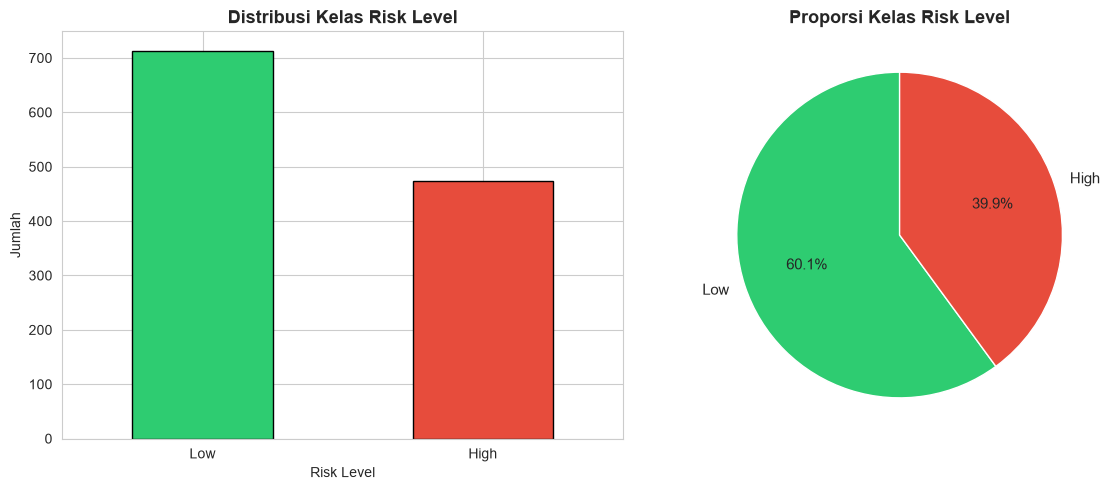

In [10]:
# Visualisasi distribusi target
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Bar plot
colors = ['#2ecc71', '#e74c3c']
order = ['Low', 'High']
df['Risk Level'].dropna().value_counts().reindex(order).plot(kind='bar', ax=axes[0], color=colors, edgecolor='black')
axes[0].set_title('Distribusi Kelas Risk Level', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Risk Level')
axes[0].set_ylabel('Jumlah')
axes[0].tick_params(axis='x', rotation=0)

# Pie chart
df['Risk Level'].dropna().value_counts().reindex(order).plot(kind='pie', ax=axes[1], colors=colors,
    autopct='%1.1f%%', startangle=90, textprops={'fontsize': 11})
axes[1].set_title('Proporsi Kelas Risk Level', fontsize=13, fontweight='bold')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()


---
## 2. Audit Kualitas Data (Anomali, Duplikat, dan Konflik Label)


### 2.1 Cek Missing Values


In [11]:
# Cek jumlah missing values per kolom
missing = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing Values': missing,
    'Persentase (%)': missing_pct.round(2)
})
print(missing_df)
print(f'\nTotal missing values: {df.isnull().sum().sum()}')


                        Missing Values  Persentase (%)
Age                                  0            0.00
Systolic BP                          5            0.41
Diastolic                            4            0.33
BS                                   2            0.17
Body Temp                            0            0.00
BMI                                 18            1.49
Previous Complications               2            0.17
Preexisting Diabetes                 2            0.17
Gestational Diabetes                 0            0.00
Mental Health                        0            0.00
Heart Rate                           2            0.17
Risk Level                          18            1.49

Total missing values: 53


### 2.2 Cek Data Duplikat (Exact Duplicates)


In [12]:
# Cek jumlah baris duplikat (semua kolom identik)
jumlah_duplikat = df.duplicated().sum()
print(f'Jumlah baris duplikat EXACT  : {jumlah_duplikat}')
print(f'Persentase duplikat          : {(jumlah_duplikat / len(df) * 100):.2f}%')


Jumlah baris duplikat EXACT  : 18
Persentase duplikat          : 1.49%


In [13]:
# Menampilkan beberapa contoh baris duplikat (jika ada)
if jumlah_duplikat > 0:
    print('Contoh baris duplikat (10 pertama):')
    display(df[df.duplicated(keep=False)].sort_values(by=list(df.columns)).head(10))


Contoh baris duplikat (10 pertama):


,Age,Systolic BP,Diastolic,BS,Body Temp,BMI,Previous Complications,Preexisting Diabetes,Gestational Diabetes,Mental Health,Heart Rate,Risk Level
592,15,120.0,80.0,6.8,98,23.0,0.0,0.0,0,0,70.0,Low
782,15,120.0,80.0,6.8,98,23.0,0.0,0.0,0,0,70.0,Low
614,17,90.0,60.0,6.9,98,22.0,0.0,0.0,0,0,76.0,Low
635,17,90.0,60.0,6.9,98,22.0,0.0,0.0,0,0,76.0,Low
615,17,90.0,63.0,6.9,98,23.0,0.0,0.0,0,0,70.0,Low
636,17,90.0,63.0,6.9,98,23.0,0.0,0.0,0,0,70.0,Low
613,18,120.0,80.0,6.9,98,21.0,0.0,0.0,0,0,76.0,Low
634,18,120.0,80.0,6.9,98,21.0,0.0,0.0,0,0,76.0,Low
630,19,120.0,80.0,7.0,98,20.0,0.0,0.0,0,0,70.0,Low
642,19,120.0,80.0,7.0,98,20.0,0.0,0.0,0,0,70.0,Low


### 2.3 Cek Konflik Label

Konflik label terjadi ketika dua baris memiliki **fitur identik** tetapi **label (Risk Level) berbeda**.  
Ini merupakan masalah serius karena model tidak dapat mempelajari pola yang konsisten dari data yang saling bertentangan.


In [14]:
# Kolom fitur (tanpa target)
feature_cols = [c for c in df.columns if c != 'Risk Level']

# Cari kombinasi fitur yang memiliki lebih dari satu label unik
konflik = df.dropna(subset=['Risk Level']).groupby(feature_cols)['Risk Level'].nunique().reset_index()
konflik = konflik[konflik['Risk Level'] > 1]
print(f'Jumlah kombinasi fitur dengan konflik label: {len(konflik)}')
print()

if len(konflik) > 0:
    # Tampilkan detail konflik
    print('Detail konflik label:')
    for _, row in konflik.iterrows():
        mask = (df[feature_cols] == row[feature_cols]).all(axis=1)
        subset = df[mask]
        print(f'\n--- Kombinasi fitur (muncul {len(subset)}x) ---')
        display(subset)
        print(f'  Label: {list(subset["Risk Level"].unique())}')


Jumlah kombinasi fitur dengan konflik label: 0



In [15]:
# Hitung total baris yang terlibat konflik label
total_baris_konflik = 0
for _, row in konflik.iterrows():
    mask = (df[feature_cols] == row[feature_cols]).all(axis=1)
    total_baris_konflik += mask.sum()

print(f'Total baris yang terlibat konflik label: {total_baris_konflik}')
print(f'Persentase dari dataset: {(total_baris_konflik / len(df) * 100):.2f}%')


Total baris yang terlibat konflik label: 0
Persentase dari dataset: 0.00%


### 2.4 Deteksi Anomali / Outlier


In [16]:
# Cek tipe data setiap kolom
print('Tipe data:')
print(df.dtypes)
print()

# Cek nilai unik per kolom
print('Nilai unik per kolom:')
for col in df.columns:
    print(f'  {col:25s} | Unik: {df[col].nunique():5d} | Min: {df[col].min()} | Max: {df[col].max()}')


Tipe data:
Age                         int64
Systolic BP               float64
Diastolic                 float64
BS                        float64
Body Temp                   int64
BMI                       float64
Previous Complications    float64
Preexisting Diabetes      float64
Gestational Diabetes        int64
Mental Health               int64
Heart Rate                float64
Risk Level                    str
dtype: object

Nilai unik per kolom:
  Age                       | Unik:    43 | Min: 10 | Max: 325
  Systolic BP               | Unik:    24 | Min: 70.0 | Max: 200.0
  Diastolic                 | Unik:    21 | Min: 40.0 | Max: 140.0
  BS                        | Unik:    84 | Min: 3.0 | Max: 19.0
  Body Temp                 | Unik:     7 | Min: 97 | Max: 103
  BMI                       | Unik:   157 | Min: 0.0 | Max: 37.0
  Previous Complications    | Unik:     2 | Min: 0.0 | Max: 1.0
  Preexisting Diabetes      | Unik:     2 | Min: 0.0 | Max: 1.0
  Gestational Diabetes    

In [17]:
# Deteksi anomali berdasarkan domain knowledge medis
print('=== Deteksi Anomali berdasarkan Domain Knowledge ===')
print()

# Age = 325 (kesalahan ketik, mustahil untuk manusia)
anomali_age_extreme = df[df['Age'] > 100]
print(f'Age > 100 tahun (kesalahan ketik/anomali) : {len(anomali_age_extreme)} baris')
if len(anomali_age_extreme) > 0:
    display(anomali_age_extreme)
print()

# BMI = 0 (secara fisiologis tidak mungkin untuk manusia hidup)
anomali_bmi = df[df['BMI'] <= 5]
print(f'BMI <= 5 (tidak valid / missing value terselubung): {len(anomali_bmi)} baris')
if len(anomali_bmi) > 0:
    display(anomali_bmi)
print()

# Heart Rate normal: 60-100 bpm
anomali_hr = df[(df['Heart Rate'] < 40) | (df['Heart Rate'] > 160)]
print(f'Heart Rate di luar batas wajar (<40 atau >160 bpm): {len(anomali_hr)} baris')
print()

# Age < 13 atau Age > 60 (rentang usia hamil yang sangat tidak umum)
anomali_age_low = df[df['Age'] < 13]
anomali_age_high = df[(df['Age'] > 60) & (df['Age'] <= 100)]
print(f'Age < 13 tahun (tidak umum untuk kehamilan): {len(anomali_age_low)} baris')
print(f'Age > 60 tahun (tidak umum untuk kehamilan): {len(anomali_age_high)} baris')
print()


=== Deteksi Anomali berdasarkan Domain Knowledge ===

Age > 100 tahun (kesalahan ketik/anomali) : 1 baris


,Age,Systolic BP,Diastolic,BS,Body Temp,BMI,Previous Complications,Preexisting Diabetes,Gestational Diabetes,Mental Health,Heart Rate,Risk Level
479,325,100.0,65.0,6.1,98,21.3,0.0,0.0,0,0,66.0,Low



BMI <= 5 (tidak valid / missing value terselubung): 1 baris


,Age,Systolic BP,Diastolic,BS,Body Temp,BMI,Previous Complications,Preexisting Diabetes,Gestational Diabetes,Mental Health,Heart Rate,Risk Level
952,24,110.0,70.0,5.1,100,0.0,0.0,1.0,0,0,78.0,Low



Heart Rate di luar batas wajar (<40 atau >160 bpm): 0 baris

Age < 13 tahun (tidak umum untuk kehamilan): 10 baris
Age > 60 tahun (tidak umum untuk kehamilan): 2 baris



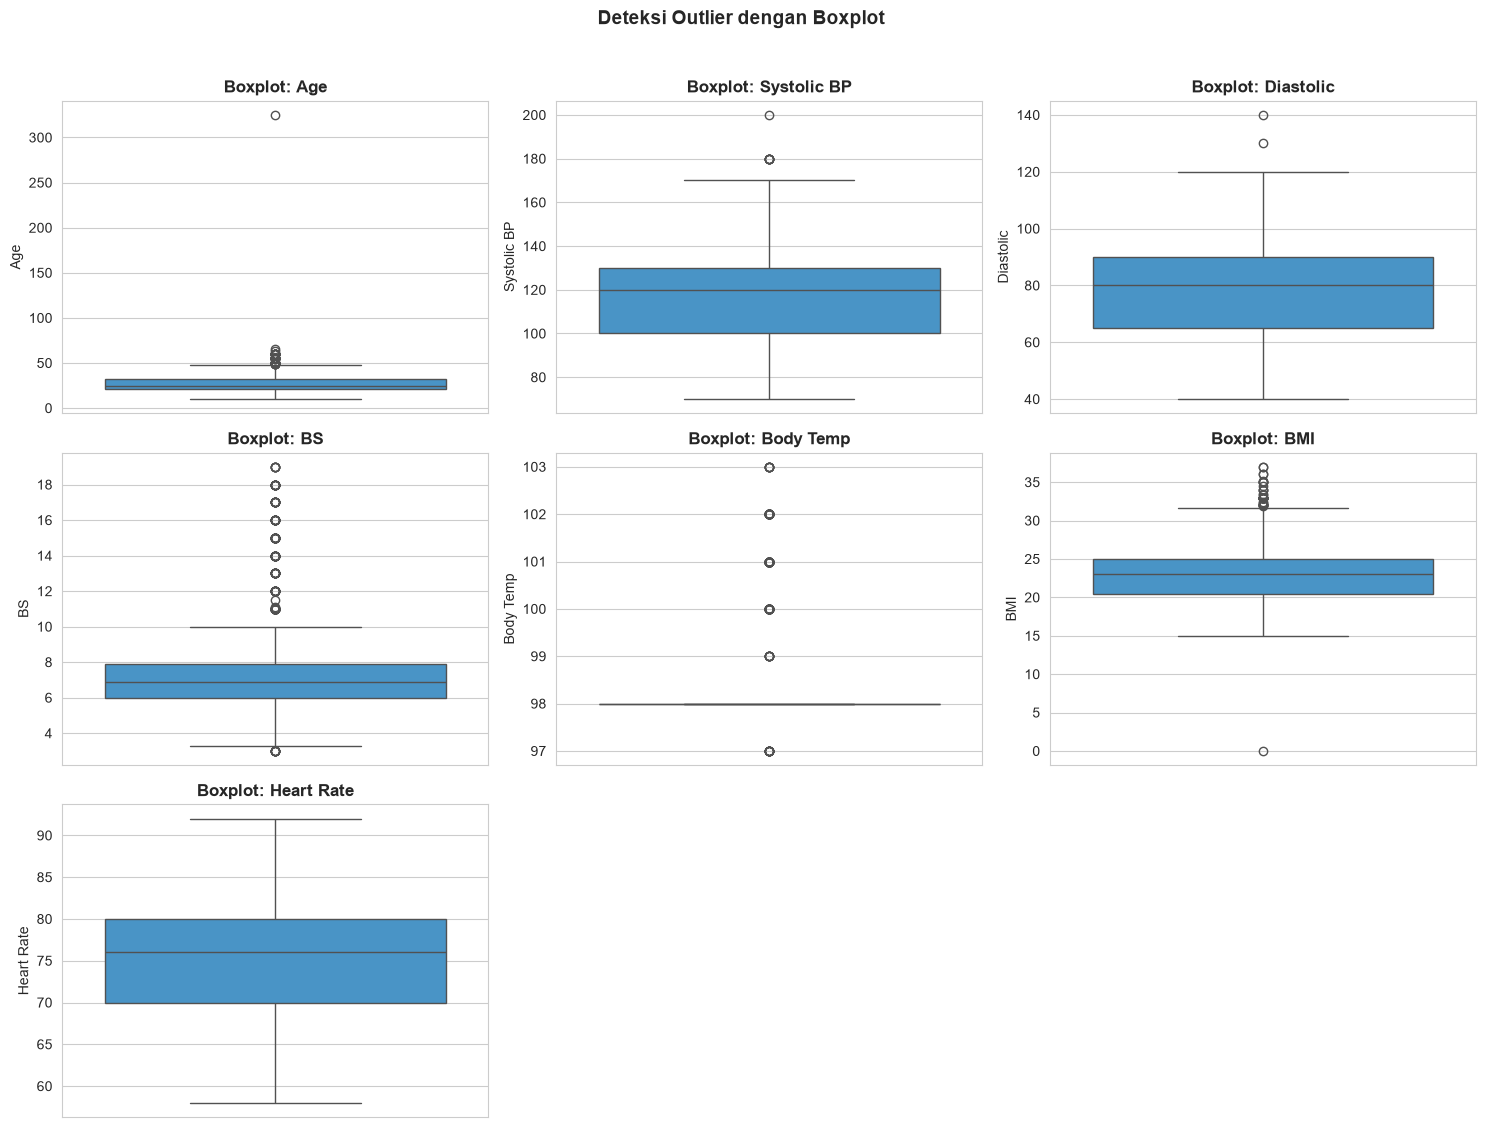

In [18]:
# Boxplot untuk semua fitur numerik
numerical_cols = ['Age', 'Systolic BP', 'Diastolic', 'BS', 'Body Temp', 'BMI', 'Heart Rate']

fig, axes = plt.subplots(3, 3, figsize=(15, 11))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.boxplot(data=df, y=col, ax=axes[i], color='#3498db')
    axes[i].set_title(f'Boxplot: {col}', fontsize=12, fontweight='bold')

for j in range(len(numerical_cols), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Deteksi Outlier dengan Boxplot', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


In [19]:
# Deteksi outlier menggunakan metode IQR
print('=== Deteksi Outlier (Metode IQR) ===')
print()

outlier_summary = []
for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    pct = len(outliers) / len(df) * 100
    print(f'{col:15s} | Batas: [{lower:6.2f}, {upper:6.2f}] | Outlier: {len(outliers):3d} ({pct:.1f}%)')
    outlier_summary.append({'Kolom': col, 'Jumlah_Outlier': len(outliers), 'Persen': pct})


=== Deteksi Outlier (Metode IQR) ===

Age             | Batas: [  4.50,  48.50] | Outlier:  58 (4.8%)
Systolic BP     | Batas: [ 55.00, 175.00] | Outlier:   8 (0.7%)
Diastolic       | Batas: [ 27.50, 127.50] | Outlier:   2 (0.2%)
BS              | Batas: [  3.15,  10.75] | Outlier: 181 (15.0%)
Body Temp       | Batas: [ 98.00,  98.00] | Outlier: 175 (14.5%)
BMI             | Batas: [ 13.62,  31.83] | Outlier:  37 (3.1%)
Heart Rate      | Batas: [ 55.00,  95.00] | Outlier:   0 (0.0%)


### 2.5 Ringkasan Temuan Audit

Sebelum melanjutkan ke Data Cleaning, berikut rangkuman masalah yang ditemukan:


In [20]:
print('=' * 65)
print('           RINGKASAN AUDIT KUALITAS DATA')
print('=' * 65)
print(f'  Total baris awal                : {len(df)}')
print(f'  Missing values total            : {df.isnull().sum().sum()}')
print(f'  Missing target (Risk Level)     : {df["Risk Level"].isnull().sum()}')
print(f'  Exact duplicates                : {jumlah_duplikat}')
print(f'  Konflik label (kombinasi fitur) : {len(konflik)}')
print(f'  Baris terlibat konflik label    : {total_baris_konflik}')
print(f'  Anomali Usia (Age > 100)        : {len(anomali_age_extreme)}')
print(f'  Anomali BMI (BMI <= 5)          : {len(anomali_bmi)}')
print(f'  Age < 13 tahun                  : {len(anomali_age_low)}')
print(f'  Age > 60 tahun                  : {len(anomali_age_high)}')
print('=' * 65)


           RINGKASAN AUDIT KUALITAS DATA
  Total baris awal                : 1205
  Missing values total            : 53
  Missing target (Risk Level)     : 18
  Exact duplicates                : 18
  Konflik label (kombinasi fitur) : 0
  Baris terlibat konflik label    : 0
  Anomali Usia (Age > 100)        : 1
  Anomali BMI (BMI <= 5)          : 1
  Age < 13 tahun                  : 10
  Age > 60 tahun                  : 2


---
## 3. Data Cleaning

Berdasarkan hasil audit di atas, berikut langkah-langkah cleaning yang dilakukan:

1. **Hapus baris dengan target hilang (Risk Level NaN)**
2. **Hapus anomali usia & ubah BMI tidak valid (0.0)**
3. **Hapus exact duplicates** (baris yang 100% identik)
4. **Imputasi missing values pada fitur** (Median untuk numerik, Modus untuk biner)
5. **Verifikasi hasil akhir**


### 3.1 Hapus Baris Target Missing & Anomali Medis


In [21]:
print(f'Jumlah baris SEBELUM hapus target missing & anomali: {len(df)}')

# 1. Hapus baris dengan Risk Level NaN (tidak dapat digunakan untuk pemodelan terarah)
df_clean = df.dropna(subset=['Risk Level']).copy()

# 2. Hapus baris anomali Age > 100 (kesalahan ketik Age = 325)
df_clean = df_clean[df_clean['Age'] <= 100].copy()

# 3. Ubah BMI == 0 menjadi NaN agar diimputasi dengan nilai yang valid
df_clean.loc[df_clean['BMI'] == 0, 'BMI'] = np.nan

print(f'Jumlah baris SETELAH hapus target missing & anomali : {len(df_clean)}')
print(f'Baris dihapus: {len(df) - len(df_clean)}')


Jumlah baris SEBELUM hapus target missing & anomali: 1205
Jumlah baris SETELAH hapus target missing & anomali : 1186
Baris dihapus: 19


### 3.2 Hapus Exact Duplicates


In [22]:
print(f'Jumlah baris SEBELUM hapus duplikat: {len(df_clean)}')

# Hapus duplikat (pertahankan kemunculan pertama)
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print(f'Jumlah baris SETELAH hapus duplikat : {len(df_clean)}')


Jumlah baris SEBELUM hapus duplikat: 1186
Jumlah baris SETELAH hapus duplikat : 1168


### 3.3 Penanganan Missing Values pada Fitur


In [23]:
print('Jumlah missing values sebelum imputasi:')
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

# Imputasi fitur numerik dengan median
numerical_features = ['Age', 'Systolic BP', 'Diastolic', 'BS', 'Body Temp', 'BMI', 'Heart Rate']
for col in numerical_features:
    if df_clean[col].isnull().sum() > 0:
        med = df_clean[col].median()
        df_clean[col] = df_clean[col].fillna(med)

# Imputasi fitur biner dengan modus (kategori terbanyak)
binary_features = ['Previous Complications', 'Preexisting Diabetes', 'Gestational Diabetes', 'Mental Health']
for col in binary_features:
    if df_clean[col].isnull().sum() > 0:
        mod = df_clean[col].mode()[0]
        df_clean[col] = df_clean[col].fillna(mod).astype(int)

print('\nJumlah missing values SETELAH imputasi:')
print(f'Missing values tersisa: {df_clean.isnull().sum().sum()}')


Jumlah missing values sebelum imputasi:
Systolic BP                4
Diastolic                  2
BS                         1
BMI                       15
Previous Complications     1
Preexisting Diabetes       1
Heart Rate                 1
dtype: int64

Jumlah missing values SETELAH imputasi:
Missing values tersisa: 0


### 3.4 Verifikasi Hasil Cleaning


In [24]:
print('=== VERIFIKASI DATA SETELAH CLEANING ===')
print()
print(f'Dimensi data bersih       : {df_clean.shape}')
print(f'Missing values            : {df_clean.isnull().sum().sum()}')
print(f'Exact duplicates tersisa  : {df_clean.duplicated().sum()}')

# Verifikasi konflik label
konflik_verify = df_clean.groupby(feature_cols)['Risk Level'].nunique().reset_index()
konflik_verify = konflik_verify[konflik_verify['Risk Level'] > 1]
print(f'Konflik label tersisa     : {len(konflik_verify)}')

# Verifikasi anomali usia & BMI
print(f'Age > 100 tersisa         : {len(df_clean[df_clean["Age"] > 100])}')
print(f'BMI <= 5 tersisa          : {len(df_clean[df_clean["BMI"] <= 5])}')
print()

# Info dataset bersih
df_clean.info()


=== VERIFIKASI DATA SETELAH CLEANING ===

Dimensi data bersih       : (1168, 12)
Missing values            : 0
Exact duplicates tersisa  : 1
Konflik label tersisa     : 0
Age > 100 tersisa         : 0
BMI <= 5 tersisa          : 0

<class 'pandas.DataFrame'>
RangeIndex: 1168 entries, 0 to 1167
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Age                     1168 non-null   int64  
 1   Systolic BP             1168 non-null   float64
 2   Diastolic               1168 non-null   float64
 3   BS                      1168 non-null   float64
 4   Body Temp               1168 non-null   int64  
 5   BMI                     1168 non-null   float64
 6   Previous Complications  1168 non-null   int64  
 7   Preexisting Diabetes    1168 non-null   int64  
 8   Gestational Diabetes    1168 non-null   int64  
 9   Mental Health           1168 non-null   int64  
 10  Heart Rate              1168 no

In [25]:
# Statistik deskriptif data bersih
df_clean.describe()


,Age,Systolic BP,Diastolic,BS,Body Temp,BMI,Previous Complications,Preexisting Diabetes,Gestational Diabetes,Mental Health,Heart Rate
count,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000
mean,27.575342,116.851884,77.250856,7.524212,98.403253,23.377055,0.178938,0.293664,0.119863,0.340753,75.892123
std,9.245549,18.765211,14.344145,3.073423,1.097269,3.820112,0.383465,0.455635,0.324940,0.474166,7.241838
min,10.000000,70.000000,40.000000,3.000000,97.000000,15.000000,0.000000,0.000000,0.000000,0.000000,58.000000
25%,21.000000,100.000000,65.000000,6.000000,98.000000,21.000000,0.000000,0.000000,0.000000,0.000000,70.000000
50%,25.500000,120.000000,80.000000,6.900000,98.000000,23.000000,0.000000,0.000000,0.000000,0.000000,76.000000
75%,32.000000,130.000000,90.000000,8.000000,98.000000,25.025000,0.000000,1.000000,0.000000,1.000000,80.000000
max,65.000000,200.000000,140.000000,19.000000,103.000000,37.000000,1.000000,1.000000,1.000000,1.000000,92.000000


Distribusi Risk Level setelah cleaning:
Risk Level
Low     695
High    473
Name: count, dtype: int64

Persentase:
Risk Level
Low     59.5
High    40.5
Name: proportion, dtype: float64



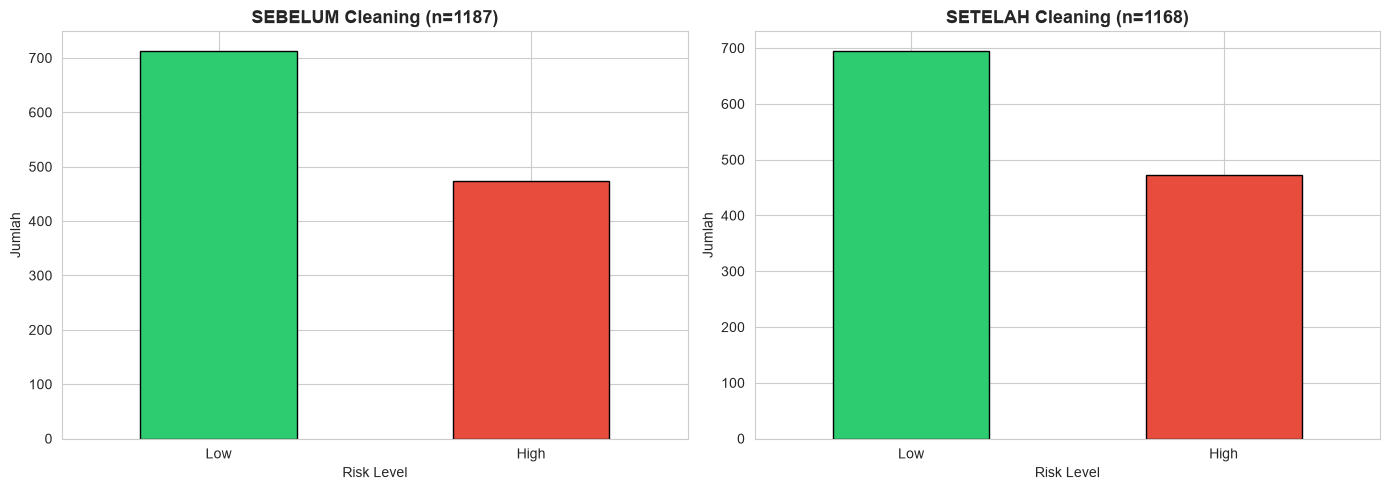

In [26]:
# Distribusi target setelah cleaning
print('Distribusi Risk Level setelah cleaning:')
print(df_clean['Risk Level'].value_counts())
print()
print('Persentase:')
print(df_clean['Risk Level'].value_counts(normalize=True).round(4) * 100)
print()

# Visualisasi perbandingan distribusi sebelum vs sesudah cleaning
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = ['#2ecc71', '#e74c3c']
order = ['Low', 'High']

# Sebelum cleaning
df['Risk Level'].dropna().value_counts().reindex(order).plot(kind='bar', ax=axes[0], color=colors, edgecolor='black')
axes[0].set_title(f'SEBELUM Cleaning (n={df["Risk Level"].dropna().shape[0]})', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Risk Level')
axes[0].set_ylabel('Jumlah')
axes[0].tick_params(axis='x', rotation=0)

# Setelah cleaning
df_clean['Risk Level'].value_counts().reindex(order).plot(kind='bar', ax=axes[1], color=colors, edgecolor='black')
axes[1].set_title(f'SETELAH Cleaning (n={len(df_clean)})', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Risk Level')
axes[1].set_ylabel('Jumlah')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()


### 3.5 Visualisasi Data Bersih


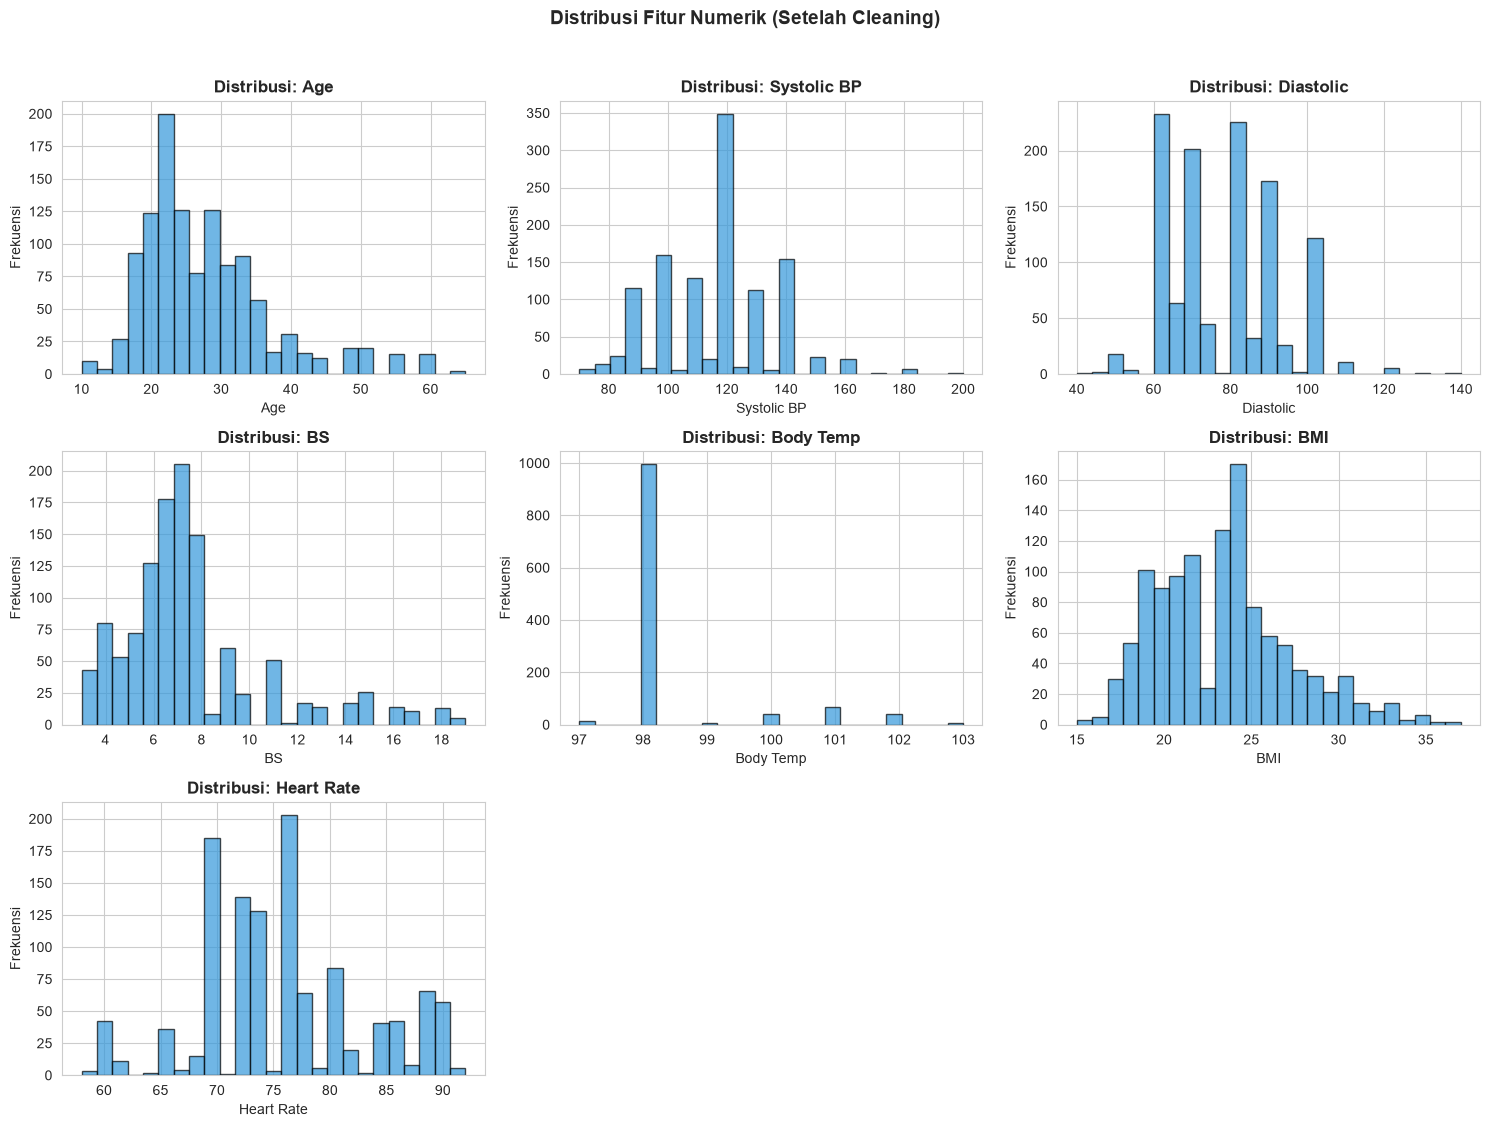

In [27]:
# Histogram distribusi setiap fitur numerik setelah cleaning
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
axes = axes.flatten()

for i, col in enumerate(numerical_features):
    df_clean[col].hist(bins=25, ax=axes[i], color='#3498db', edgecolor='black', alpha=0.7)
    axes[i].set_title(f'Distribusi: {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frekuensi')

for j in range(len(numerical_features), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Distribusi Fitur Numerik (Setelah Cleaning)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


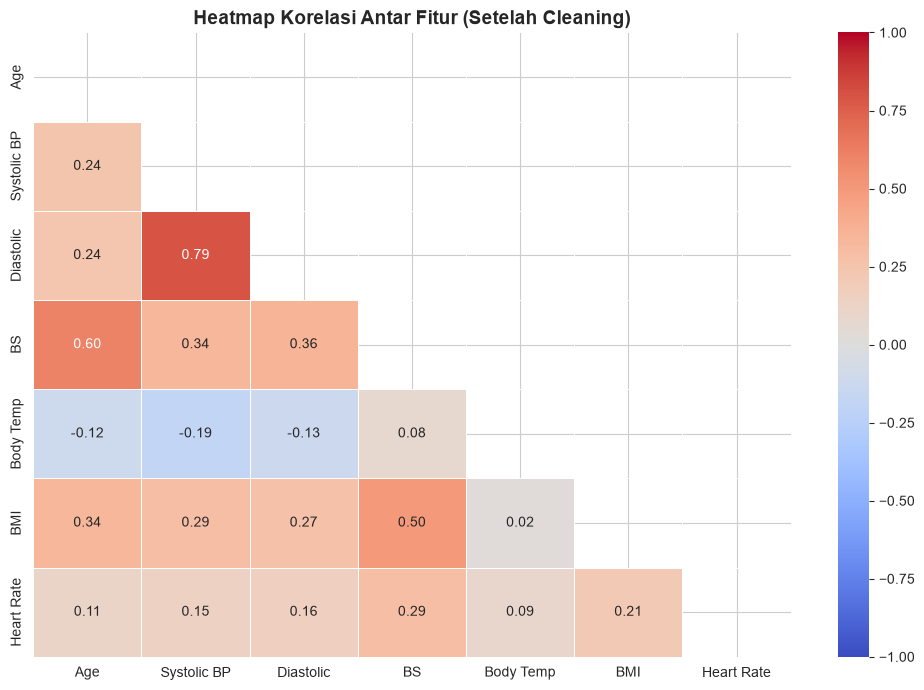

In [28]:
# Heatmap korelasi data bersih
plt.figure(figsize=(10, 7))
corr_matrix = df_clean[numerical_features].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', mask=mask,
            linewidths=0.5, vmin=-1, vmax=1, center=0)
plt.title('Heatmap Korelasi Antar Fitur (Setelah Cleaning)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


### 3.6 Ringkasan Cleaning

Data telah dibersihkan dan siap untuk tahap selanjutnya (**Poin 4: Stratified Train-Test Split**).


In [29]:
print('=' * 65)
print('          RINGKASAN PROSES DATA CLEANING')
print('=' * 65)
print(f'  Baris awal (raw)                     : {len(df)}')
print(f'  Baris dihapus (target NaN)           : {df["Risk Level"].isnull().sum()}')
print(f'  Baris dihapus (anomali Age 325)      : {len(anomali_age_extreme)}')
print(f'  Baris dihapus (exact duplicate)       : {jumlah_duplikat}')
print(f'  Baris diimputasi (missing features)  : {len(df_clean) - len(df.dropna())}')
print(f'  Baris akhir (clean)                   : {len(df_clean)}')
print(f'  Persen data dipertahankan             : {(len(df_clean) / len(df) * 100):.1f}%')
print('=' * 65)
print()
print('Data bersih tersedia di variabel: df_clean')


          RINGKASAN PROSES DATA CLEANING
  Baris awal (raw)                     : 1205
  Baris dihapus (target NaN)           : 18
  Baris dihapus (anomali Age 325)      : 1
  Baris dihapus (exact duplicate)       : 18
  Baris diimputasi (missing features)  : 2
  Baris akhir (clean)                   : 1168
  Persen data dipertahankan             : 96.9%

Data bersih tersedia di variabel: df_clean


In [30]:
# Simpan data yang sudah bersih
df_clean.to_csv('Maternal_Risk_Clean.csv', index=False)
print('Data bersih berhasil disimpan ke: Maternal_Risk_Clean.csv')
print(f'Dimensi data bersih: {df_clean.shape[0]} baris x {df_clean.shape[1]} kolom')


Data bersih berhasil disimpan ke: Maternal_Risk_Clean.csv
Dimensi data bersih: 1168 baris x 12 kolom
